# 05 · Robustness and small-sample inference

**Who this is for:** researchers and allocators deciding whether a backtest deserves belief. With 10–30 stocks and a few years of data, a single *t*-statistic is not evidence. This notebook runs the full battery on the open dataset (never-seen period):

1. **Identity versus timing** (Lo 2008, plus a causal split). Is the book just long the winners of a hindsight-selected universe?
2. **Placebos** through the identical construction, and **leave-one-out** rebuilds.
3. **Researcher degrees of freedom.** A multiverse of specifications, Hansen's SPA test, PBO and the deflated Sharpe ratio.
4. **Against the toolkit.** Romano–Wolf step-down tests against 16 institutional books.
5. **Bayesian inference.** Posterior Sharpe ratios under sceptical priors, random-effects meta-analysis across samples (with the predictive distribution for the *next* universe), empirical-Bayes shrinkage of a signal search, and Bayes factors.
6. **Power.** What could this sample have detected at all?

In [1]:
# fmflow-setup: runs as-is everywhere. In an installed environment it only locates the repository; on Google Colab,
# Binder or a Jupyter without the package, it downloads the repository once and installs it (about a minute).
import importlib, importlib.util, os, shutil, subprocess, sys
from pathlib import Path

REPO_URL = os.environ.get("FMFLOW_REPO_URL", "https://github.com/bahakh19/first-mover-flow")   # set it to use a fork


def _run(cmd: list, what: str, hint: str = "") -> None:
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(f"{what} failed:\n{(r.stderr or r.stdout).strip()[-1500:]}\n{hint}")


_here = Path.cwd()
_root = next((p for p in (_here, *_here.parents, _here / "first-mover-flow") if (p / "src" / "fmflow").is_dir()), None)
if _root is None:                                                  # notebooks need the repository's data/ folder
    _root = (_here / "first-mover-flow").resolve()
    print(f"Downloading {REPO_URL} ...")
    if shutil.which("git"):
        _run(["git", "clone", "-q", "--depth", "1", REPO_URL, str(_root)], f"git clone {REPO_URL}",
             "Is the repository public? For a fork or a local copy, set the environment variable FMFLOW_REPO_URL.")
    else:                                                          # no git: the GitHub zip archive of the main branch
        import io, urllib.request, zipfile
        with urllib.request.urlopen(REPO_URL.rstrip("/") + "/archive/refs/heads/main.zip") as _r:
            zipfile.ZipFile(io.BytesIO(_r.read())).extractall(_here)
        (_here / (REPO_URL.rstrip("/").split("/")[-1] + "-main")).rename(_root)
if importlib.util.find_spec("fmflow") is None:
    print("Installing fmflow and its dependencies (about a minute) ...")
    _target = f"{_root}[plot]"
    if importlib.util.find_spec("pip"):
        _run([sys.executable, "-m", "pip", "install", "-q", "-e", _target], "pip install")
    elif shutil.which("uv"):                                       # uv-created environments have no pip
        _run(["uv", "pip", "install", "-q", "--python", sys.executable, "-e", _target], "uv pip install")
    else:
        raise RuntimeError("this kernel has neither pip nor uv: install the package from a terminal (INSTALL.md)")
    sys.path.insert(0, str(_root / "src"))
    importlib.invalidate_caches()
os.chdir(_root / "notebooks")
print("fmflow", importlib.import_module("fmflow").__version__, "| repository:", _root)

fmflow 2.2.4 | repository: /home/claude/work/v22/repo


In [2]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from fmflow import StrategyConfig, load_prices, load_ratings, run_strategy
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE, ORANGE, GREEN, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#9a9a9a"
P = load_prices(ROOT / "data/open/MarketData_Normalized.csv")
R = load_ratings(ROOT / "data/open/Ratings_Normalized.csv", P)
SIG = pd.read_csv(ROOT / "tests/fixtures/open_sig_gjr.csv.gz", index_col=0, parse_dates=True)   # cached GARCH forecasts
EV = slice("2024-01-05", "2026-08-05")                                                          # pre-registered window
CFG = StrategyConfig.fmf_n_scalable()                                                           # leg fraction 0.4
out = run_strategy(P, R, CFG, sig_vol=SIG)
print(f"{out.prices.shape[1]} stocks, {len(out.prices)} sessions, {len(out.ratings):,} accepted ratings")
from fmflow.analytics.metrics import perf_stats
from fmflow.benchmarks import comparable_books
net = out.net_returns.loc[EV]

30 stocks, 899 sessions, 2,363 accepted ratings


## 1. Identity versus timing

The time-shift placebo keeps each stock's habitual rank, so it cannot tell skill in timing apart from a static tilt towards stocks that did well. The causal split separates them:
- the **static** book holds each stock's expanding mean of *past* weights;
- the **timing** book holds today's deviation from that mean.

Both books are tradable, and they sum to the strategy.

Lo (2008): {'total': 0.1078, 'passive': 0.0736, 'active': 0.0342, 'active_share': 0.3175}


,ann_mean,t_hac,se_daily,Sharpe
static,-0.018,-0.871,0.000,-0.487
timing,0.125,2.214,0.000,1.327
total,0.108,1.763,0.000,1.073


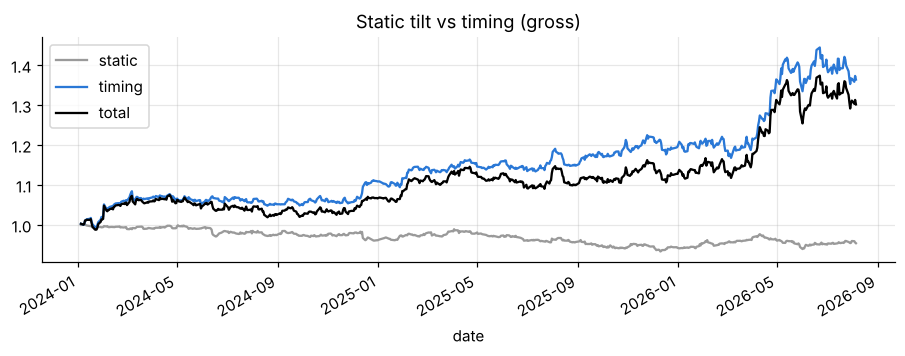

In [3]:
from fmflow.analytics.attribution import lo_decomposition, static_timing_books, mean_with_hac, stock_contributions
print("Lo (2008):", {k: round(v, 4) for k, v in lo_decomposition(out.weights, out.returns, EV).items()})
stb = static_timing_books(out.weights, out.returns).loc[EV]
display(pd.DataFrame({c: {**mean_with_hac(stb[c]), "Sharpe": perf_stats(stb[c])["Sharpe"]} for c in stb}).T)
(1 + stb).cumprod().plot(figsize=(10, 3), color=[GREY, BLUE, "k"], title="Static tilt vs timing (gross)"); plt.show()

## 2. Placebos and leave-one-out

There are three placebo nulls:
- IID random scores;
- stock-label permutations;
- circular time-shifts.

Each counterfeit score passes through the **identical** construction, so only the information in the signal differs. Leave-one-out rebuilds the entire pipeline (cleaning, snapshot, signals, ranks, book) without each stock in turn.

draws  observed  null_median  null_95     p
OOS iid         200.000     1.046       -0.218    0.854 0.025
    permutation 300.000     1.046       -0.110    1.154 0.060
    time_shift  108.000     1.046        0.070    2.116 0.229

leave-one-out Sharpe: min 0.74, median 1.04, max 1.33 over 30 rebuilds


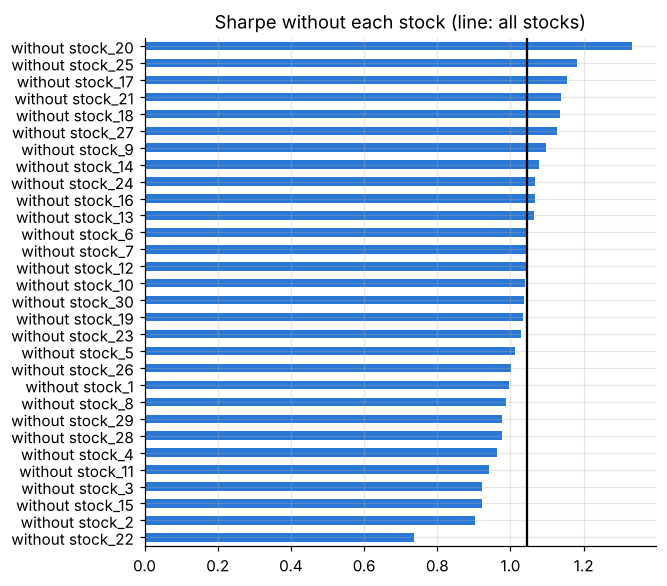

In [4]:
from fmflow.robustness import strategy_placebo, leave_one_out
pl = strategy_placebo(out, {"OOS": EV}, n_iid=200, n_perm=300, shift_step=6)
display(pl)
loo = leave_one_out(P, R, CFG, {"OOS": EV}, sig_vol=SIG)
print(f"leave-one-out Sharpe: min {loo['Sharpe OOS'].min():.2f}, median {loo['Sharpe OOS'].median():.2f}, "
      f"max {loo['Sharpe OOS'].max():.2f} over {len(loo) - 1} rebuilds")
loo["Sharpe OOS"].drop("all stocks").sort_values().plot.barh(figsize=(6, 6), color=BLUE); plt.axvline(net.mean() / net.std() * 252 ** 0.5, color="k")
plt.title("Sharpe without each stock (line: all stocks)"); plt.show()

## 3. Researcher degrees of freedom: the multiverse

The full pipeline is re-run over every reasonable choice:
- signal windows and leader/herder definitions;
- target expiry, including the quarterly (63-session) calibration;
- event size, legs, tranches, allocator and the signal set.

Then the family is tested as a whole:
- **SPA** (Hansen 2005) asks whether *any* specification beats zero after accounting for the search;
- **PBO** asks whether the in-sample ranking persists;
- the **ensemble** holds every specification at once, so it involves no selection at all.

121 specifications: 98% with Sharpe > 0, median 0.66, 10th pct 0.22


SPA p = 0.087;  PBO = 0.28;  ensemble Sharpe = 0.82
DSR of the frozen specification against this family: {'n_eff': 34.768, 'SR0_daily': 0.051, 'PSR': 0.953, 'DSR': 0.647}


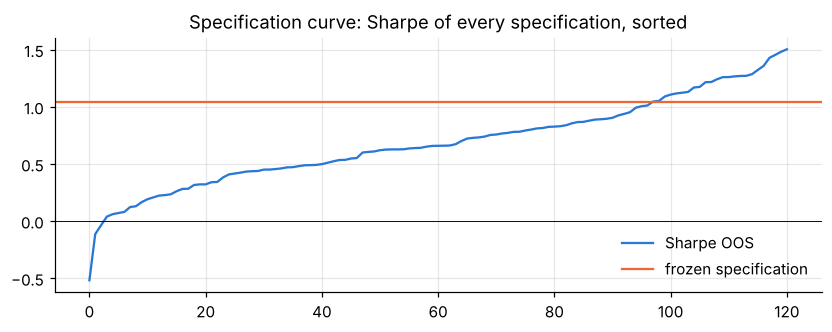

In [5]:
from fmflow.robustness import multiverse
from fmflow.analytics.snooping import spa_test
from fmflow.analytics.inference import cscv_pbo, deflated_sharpe
GRID = {"leader_gap": [5, 10, 15, 20], "herd_window": [(2, 10), (3, 15), (5, 20)], "lmh_window": [63, 126, 189, 252],
        "breadth_window": [42, 63, 126], "tranche_period": [21, 42, 63, 84], "allocator": ["EW", "IV-GJR"],
        "data.tp_expiry_days": [63, 126, 252], "data.event_min_ratings": [4, 5, 6], "legs": [0.3, 0.4, 0.5]}
tab, nets = multiverse(P, R, CFG, GRID, {"OOS": EV}, sig_vol=SIG, mode="random", n_random=120, seed=1, n_jobs=2)
s = tab["Sharpe OOS"].dropna()
fam = nets.loc[EV].fillna(0.0)
ens = nets.mean(axis=1).loc[EV]
print(f"{len(s)} specifications: {100 * (s > 0).mean():.0f}% with Sharpe > 0, median {s.median():.2f}, 10th pct {s.quantile(.1):.2f}")
print(f"SPA p = {spa_test(fam)['p_value']:.3f};  PBO = {cscv_pbo(fam, 12)['PBO']:.2f};  ensemble Sharpe = {perf_stats(ens)['Sharpe']:.2f}")
print("DSR of the frozen specification against this family:", {k: round(v, 3) for k, v in deflated_sharpe(net.values, fam).items()})
ax = s.sort_values().reset_index(drop=True).plot(figsize=(9, 3), color=BLUE, title="Specification curve: Sharpe of every specification, sorted")
ax.axhline(s.loc["base"], color=ORANGE, label="frozen specification"); ax.axhline(0, color="k", lw=0.6); ax.legend(frameon=False); plt.show()

## 4. Against the institutional toolkit, with family-wise error control

Each comparable is scaled to FMF-N's volatility, so the tests are tests of Sharpe-ratio differences.
- **Romano–Wolf** step-down tests ask which comparables FMF-N significantly beats;
- the reverse **SPA** test asks whether *any* comparable significantly beats FMF-N.

In [6]:
from fmflow.analytics.snooping import romano_wolf
books = comparable_books(out)
scale = lambda x: x.loc[EV] / x.loc[EV].std() * net.std()
D = pd.DataFrame({k: net - scale(v) for k, v in books.items()}).dropna()
display(romano_wolf(D, n_boot=1000).round(3))
print("SPA p, H0 'no comparable beats FMF-N':", round(spa_test(pd.DataFrame({k: scale(v) - net for k, v in books.items()}).dropna())["p_value"], 3))

,mean,t_boot,p_raw,p_romano_wolf,reject
Betting-against-beta (low beta),0.001,2.089,0.037,0.139,False
Low analyst dispersion,0.001,1.843,0.042,0.206,False
Low volatility (60d),0.001,1.684,0.068,0.268,False
Short-term reversal (1m),0.000,1.362,0.112,0.399,False
Multi-factor: mom + low vol + reversal,0.000,1.292,0.118,0.430,False
52-week-high proximity,0.000,1.231,0.122,0.430,False
Residual momentum (Blitz et al.),0.000,1.090,0.146,0.449,False
Target-price upside (consensus),0.000,1.070,0.145,0.449,False
6-1 momentum,0.000,1.014,0.173,0.449,False
12-1 momentum (Jegadeesh-Titman),0.000,0.942,0.192,0.459,False


SPA p, H0 'no comparable beats FMF-N': 0.857


## 5. Bayesian inference

- **Posterior Sharpe ratio.** The Bayesian bootstrap of weekly returns is nonparametric, so skew and fat tails come from the data. It is shown under a flat prior, a sceptical N(0, 1) prior and a very sceptical N(0, 0.5) prior on the annual Sharpe ratio.
- **Random-effects meta-analysis.** The samples are combined *without* assuming one true effect, and the model reports the predictive distribution of the effect in a **new** universe.
- **Empirical-Bayes shrinkage.** This shrinks a signal search towards the family. It is applied to the 18-signal development search reported in the paper.

In [7]:
from fmflow.analytics.bayes import bayesian_sharpe, random_effects_meta, shrink_normal_means, bayes_factor_normal
display(pd.DataFrame({p: bayesian_sharpe(net, prior_sr_sd=v, n_draws=30000).summary() for p, v in
                      (("flat", None), ("sceptical N(0,1)", 1.0), ("very sceptical N(0,0.5)", 0.5))}).T)
# LMH information coefficient in the three non-overlapping samples of the paper (development, holdout, never-seen period)
ic, se = [0.095, 0.129, 0.096], [0.065, 0.070, 0.053]
m = random_effects_meta(ic, se, ["development 2017-19", "holdout 2020-21", "never-seen 2024-26"], tau_scale=0.05)
display(m["table"])
print(f"pooled IC: {m['mu'].summary()['mean']:.3f}  P(IC > 0) = {m['P(mu>0)']:.3f}  "
      f"P(IC > 0 in the NEXT universe) = {m['P(theta_new>0)']:.3f}")
print("Bayes factors BF10 (prior sd 0.1):", [round(bayes_factor_normal(a, b, 0.1), 2) for a, b in zip(ic, se)])
lib18 = pd.Series({"leader_minus_herd": 2.458, "disp_chg": 1.268, "analyst_conviction_shock": 1.070, "breadth_21": 0.786,
                   "fresh_upside_126": 0.716, "breadth_126": 0.713, "fresh_upside_63": 0.610, "ear_drift": 0.548,
                   "resid_mom_12_1": 0.448, "low_beta_126": 0.378, "breadth_42": 0.067, "neg_ivol_60": 0.062,
                   "diffusion_63": -0.130, "rev_5": -0.656, "breadth_ts_z": -0.819, "neg_max5": -1.993,
                   "cons_chg_resid_px": -2.268, "high52": -2.827})
display(shrink_normal_means(lib18).head(5))

,mean,median,sd,hdi90_low,hdi90_high,P(>0),P(>0.5),P(>1)
flat,1.038,1.051,0.590,0.049,1.994,0.957,0.819,0.534
"sceptical N(0,1)",0.771,0.774,0.514,-0.077,1.609,0.929,0.701,0.335
"very sceptical N(0,0.5)",0.427,0.431,0.390,-0.231,1.063,0.860,0.427,0.070


,estimate,se,shrunk_mean,P(theta>0)
development 2017-19,0.095,0.065,0.102,0.986
holdout 2020-21,0.129,0.070,0.109,0.992
never-seen 2024-26,0.096,0.053,0.102,0.993


pooled IC: 0.105  P(IC > 0) = 0.986  P(IC > 0 in the NEXT universe) = 0.955
Bayes factors BF10 (prior sd 0.1): [2.05, 3.35, 3.19]


,t,shrunk_t,P(theta>0),shrinkage_B
leader_minus_herd,2.458,1.064,0.948,0.573
disp_chg,1.268,0.555,0.802,0.573
analyst_conviction_shock,1.070,0.471,0.764,0.573
breadth_21,0.786,0.349,0.704,0.573
fresh_upside_126,0.716,0.320,0.688,0.573


## 6. Power: what could this sample detect?

Detecting a true mean IC of 0.10 takes:
- with 10 stocks over three years, a coin flip (about 56% power);
- with 30 stocks, about 90% power.

A *null* result in a small universe is therefore uninformative, and a positive one must be judged by its replication rather than its *t*-statistic.

In [8]:
from fmflow.analytics.power import mde_ic, ic_power
mde = pd.DataFrame({f"{y}y": {n: mde_ic(n, int(y * 12)) for n in (10, 20, 30, 50, 100)} for y in (3, 5, 10)})
display(mde.rename_axis("stocks"))
print("power for IC = 0.10:", {n: round(ic_power(0.10, n, 36), 2) for n in (10, 20, 30, 50)})

,3y,5y,10y
stocks,,,
10,0.138,0.107,0.076
20,0.095,0.074,0.052
30,0.077,0.060,0.042
50,0.059,0.046,0.032
100,0.042,0.032,0.023


power for IC = 0.10: {10: 0.56, 20: 0.83, 30: 0.94, 50: 0.99}
